# SQDMetal Xmon capacitance-simulation example — cross transmon with an open-ended coupled readout (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/Palace_Capacitance_Xmon_Gmsh.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/xmon_cap_sim.md`): a Quantum
Metal design meshed with Gmsh for a Palace capacitance run on silicon (280 µm); it stores no outputs. One grounded
`TransmonCross` with two claws (readout east, bus west). The readout claw runs a 3.7 mm `RouteMeander` to an
`OpenToGround` 40 µm below a straight transmission line between two small `LaunchpadWirebond`s; the meander's
300 µm start straight runs parallel to the line, so the line couples through an open-ended coupled section.

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 4.6 × 2.4 mm centred on (0, −1) mm | the 7.5 × 7.5 mm Quantcore die with its frame, device ID "SQD-XCS"; the source area in its centre (Designer = source + (2300, 2200) µm before centring) |
| pads | two `LaunchpadWirebond`s at x = ±2 mm (1465 µm from our die edges) | the same launchpads **on the die edges**: outer etch 100 µm (`frame.pad_edge`) from the west / east edge (PDK pad rule); the line between them is 2.7 mm longer |
| substrate | silicon, 280 µm | sapphire 650 µm, εr 10.25 |
| junctions | none (a capacitance-only run) | the Quantcore trilayer junction at the PDK nominal: 0.5 × 0.6 µm, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF |
| cheese | none (`cap_sim.add_ground_plane()` without holes; the spec: "no fill") | the PDK band (chip `cheese` `"auto"`, at least 4 µm clear of 3/0) |
| components | `TransmonCross` (`bus_01` claw 95 µm), `RouteMeander` 3.7 mm, `RoutePathfinder`, `OpenToGround` | kept through the `metal:` wrapper with the source options; the meander + `OpenToGround` are one qcc open hanger route |
| placement | — | centred in the die (the source content sat 214 µm above the centre; shifted) |

**Substituted:** the `OpenToGround` + `RouteMeander` pair is one qcc route ending in an open hanger (`end="open"`,
6 µm open gap): electrically the same λ/2-type line, open at the coupled end and capacitive at the claw; the
meander is KQC's on the leg between the claw and the line (r = 99.9 µm, the source fillet). The `TL`
`RoutePathfinder` is a straight qcc route. **Kept:** the `bus_01` claw is left open, as in the source.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two launchpads, the transmission line between them, the cross transmon, its open-ended readout under the line, and then the whole chip (the sim group, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `xmon_cap_sim.v1.ipynb`; both save the same `xmon_cap_sim.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/xmon_cap_sim/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "xmon_cap_sim"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 2300, 2200                              # Metal's chip is centred on (0, -1) mm

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** The source sets no junction (a capacitance run); the rebuild draws the PDK
nominal trilayer junction in the cross (`trilayer_junction("metal:TransmonCross")`: `junction_type` for the cell,
L_J / C_J for the LOM). Expected f_q ≈ 5.8–6.0 GHz (the pre-rebuild build assumed 12 nH and gave 4.6 GHz).

In [5]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonCross")     # nominal: 0.5 × 0.6 µm, R_n 45 kΩ
print("cell parameters:", JJ_PARAMS, "| LOM junction:", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Junction'} | LOM junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, the qubit,
its readout resonator, and then the whole chip. Each segment is one cell with one picture of the chip so far (live,
KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the line is
drawn before the qubit and the readout after it. Coordinates are the source's + (`X0`, `Y0`) until the centring in
Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID SQD-XCS) |
| 2 | the two launchpads (`LaunchpadWirebond`), on the west / east die edges |
| 3 | the readout line `TL` between them |
| 4 | the qubit: a `TransmonCross` with its two claws and the trilayer junction |
| 5 | the readout `R1`, from the readout claw to an open hanger 40 µm below the line |
| 6 | the coupling: none (the `bus_01` claw stays open, as in the source) |
| 7 | the control routing: none |
| 8 | the whole chip: the sim group, the centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so the source's 4.6 × 2.4 mm area
sits in its middle (every source position + (2300, 2200) µm). The PDK frame: L dicing markers (1000/0), 3 × 3
alignment grids (1001/0), the chip boundary (100/0), the device ID on a free edge. The chip `cheese` stays
`"auto"`: the source has no cheese, so the PDK band is drawn.

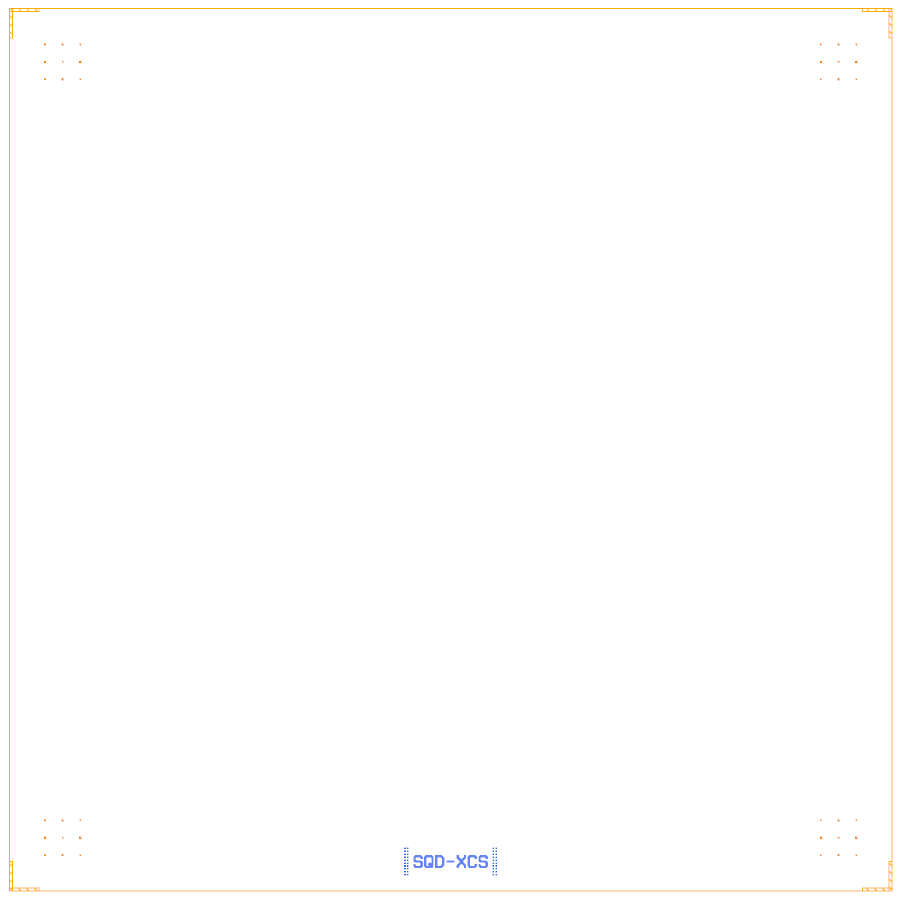

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/xmon_cap_sim/s1_die.png')

In [6]:
d = Designer("xmon_cap_sim", box=(-1450, -2550, 6050, 4950), chip={"name_chip": "SQD-XCS"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(900, 900), width=360)

## Design 2 · Bond pads: the two launchpads and the pad rule

**PDK rule:** a bond pad's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. The source's
two `LaunchpadWirebond`s (103 × 103 µm pad, 60 µm gap, 30 µm lead) sat at x = ±2 mm, 1465 µm inside our die; here
each is added at the source's y with `edge="w"` / `edge="e"`, which slides it perpendicular to that edge until
its etch is 100 µm from it (each pad moves 1365 µm out). The table measures the result.

The first picture is the chip so far, the second zooms on the west launchpad.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

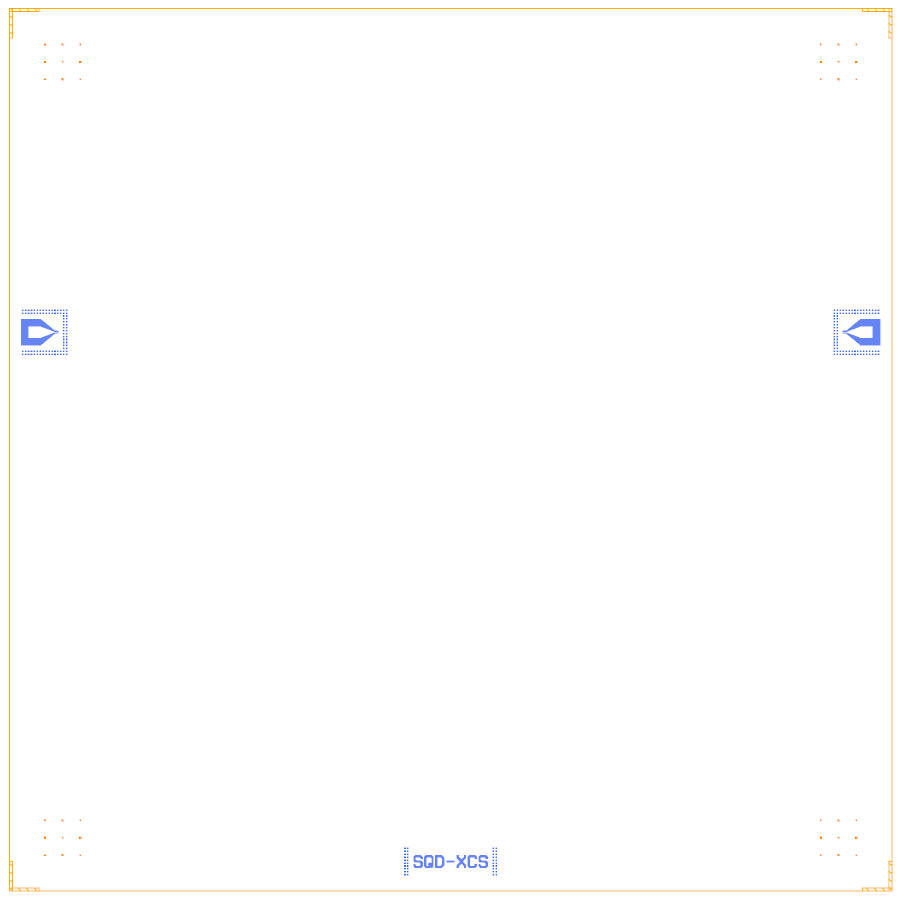

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `LP1`, `LP2`.

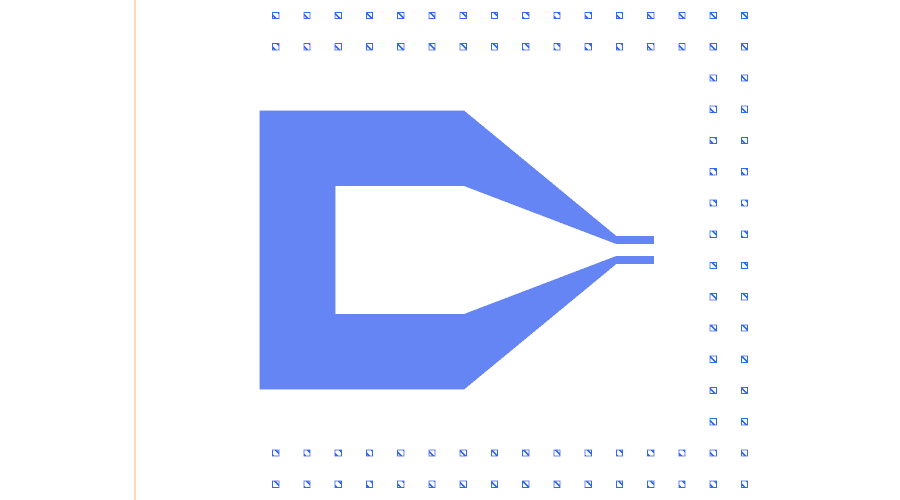

In [7]:
LP = dict(lead_length=30, pad_height=103, pad_width=103, pad_gap=60)
with d.batch():
    lp1 = d.add("LP1", "metal:LaunchpadWirebond", at=(X0 - 2000, Y0), rot=0, edge="w", **LP)
    lp2 = d.add("LP2", "metal:LaunchpadWirebond", at=(X0 + 2000, Y0), rot=180, edge="e", **LP)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(900, 900), width=360)
x, y = port_xy(d, "LP1.tie")
snap(d, STEPS / "2_pad.png", box=(-1460, y - 200, x + 100, y + 200), size=(900, 500), width=420);

## Design 3 · Readout: the transmission line

**The line** `TL` between the two launchpads' `tie` pins (10/6 µm, straight; the source's `RoutePathfinder`). With
the launchpads on the die edges it is 2.7 mm longer than the source's; a 50 Ω through-line, so its length sets no
frequency. The readout hangs on it (Design 5).

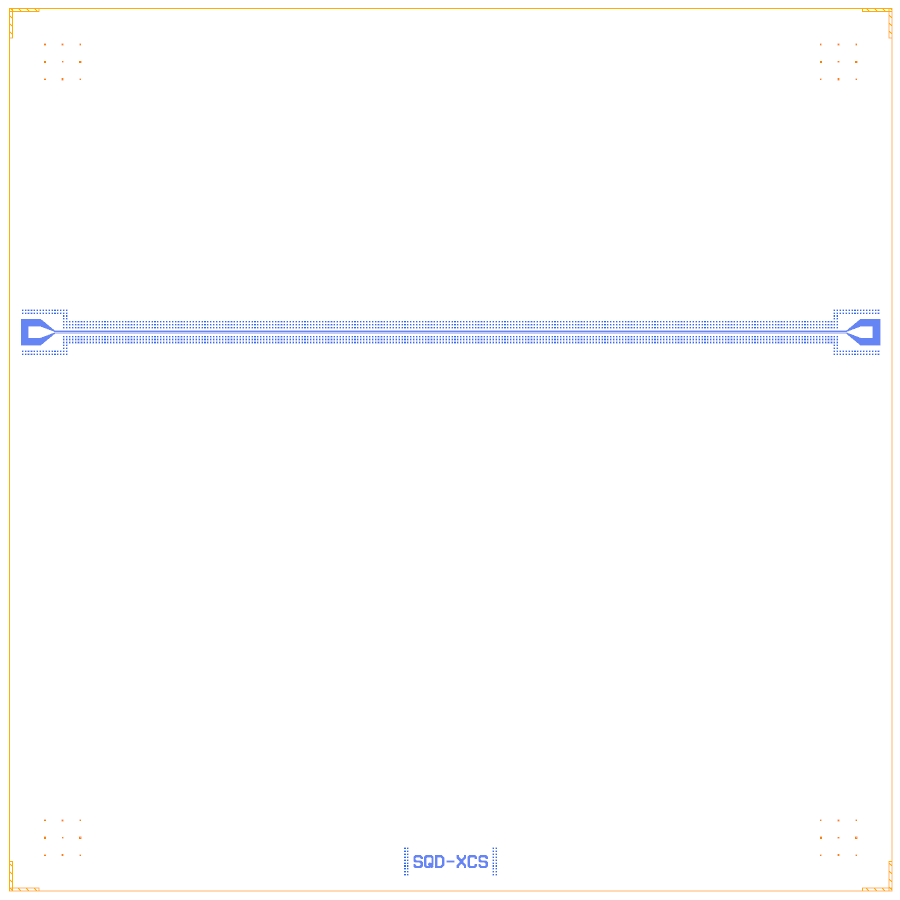

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `TL`.

WindowsPath('build/snapshots/xmon_cap_sim/s3_line.png')

In [8]:
with d.batch():
    tl = d.route("TL", lp1.tie, lp2.tie, r=90)
layout_step(d, STEPS / "s3_line.png", size=(900, 900), width=360)

## Design 4 · Qubit placement: the cross transmon

The Quantum Metal `TransmonCross` through the `metal:` wrapper (Metal options as cell parameters; bare numbers on
length options are µm), with the source's connection pads: `readout` at 0° and `bus_01` at 180° with a 95 µm
claw; the other options are Metal's defaults (arms 200 µm long, 20 µm wide, 20 µm gap). Ports: the claws
`readout` and `bus_01`, and the junction attachment points `squid_a` / `squid_b`. The trilayer junction of the junction cell above is drawn in the cross. The first picture is the chip so far, the second zooms on the qubit.

<metal:TransmonCross Q1 ports=['bus_01', 'readout', 'squid_a', 'squid_b']>


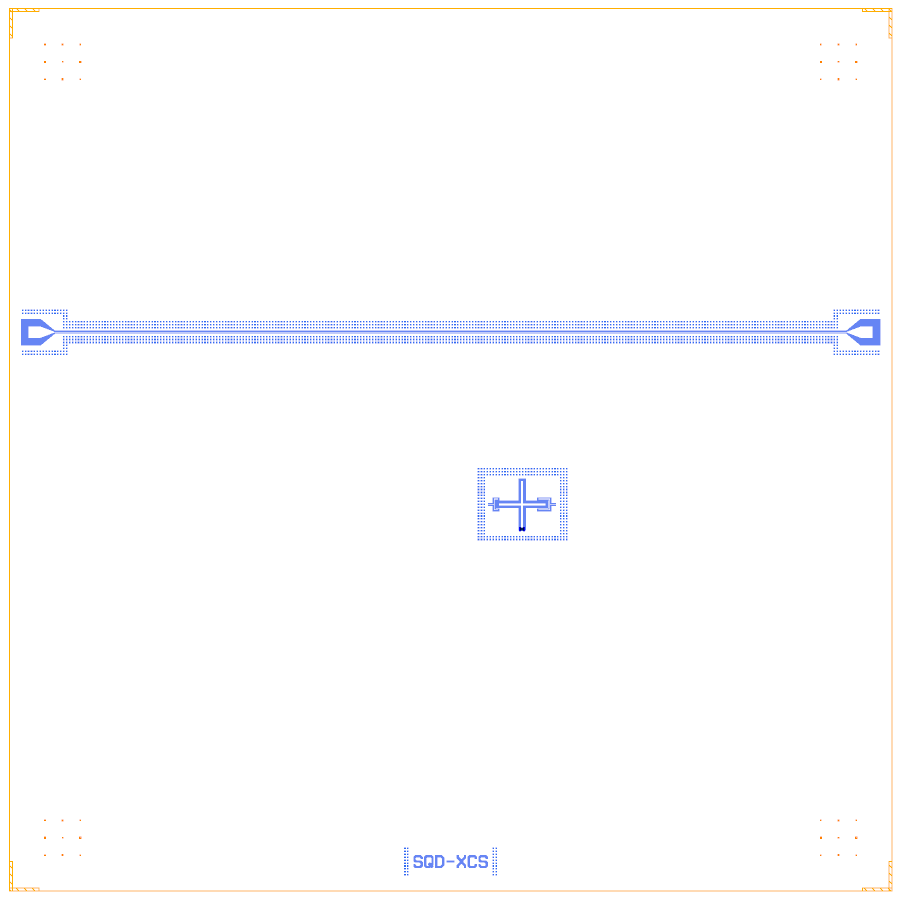

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

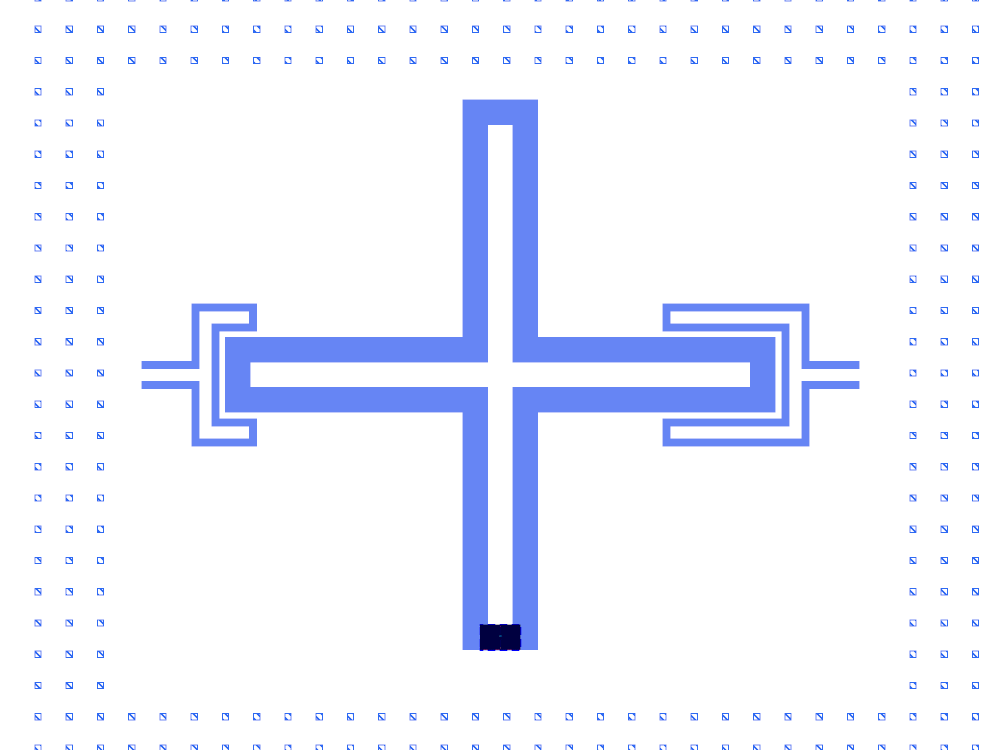

In [9]:
q1 = d.add("Q1", "metal:TransmonCross", at=(X0 + 607.5, Y0 - 1464),
           connection_pads={"bus_01": {"connector_location": "180", "claw_length": 95},
                            "readout": {"connector_location": "0"}},
           junction=JUNCTION, **JJ_PARAMS)
print(q1)
qx, qy = X0 + 607.5, Y0 - 1464
layout_step(d, STEPS / "s4_qubit.png", size=(900, 900), width=360)
snap(d, STEPS / "3_qubit.png", box=(qx - 400, qy - 300, qx + 400, qy + 300), size=(1000, 750), width=420);

## Design 5 · Readout: the open-ended readout under the line

**The readout** from the `readout` claw: west to a waypoint, then KQC's meander up to the coupled section and an
**open** hanger end 40 µm below the line (`end="open"`: 6 µm open gap; centre spacing 40 µm = 5 + 6 + 18 + 6 + 5, so
`ground_gap=18`), 3700 µm in total. `TL.hanger(near=(x, y), ...)` centres the 400 µm coupled part (the source's
300 µm `start_straight` plus its bend) at the line point nearest (1900, y_TL) — the source's position, independent of
where the line starts, so moving the pads to the edge does not move it.

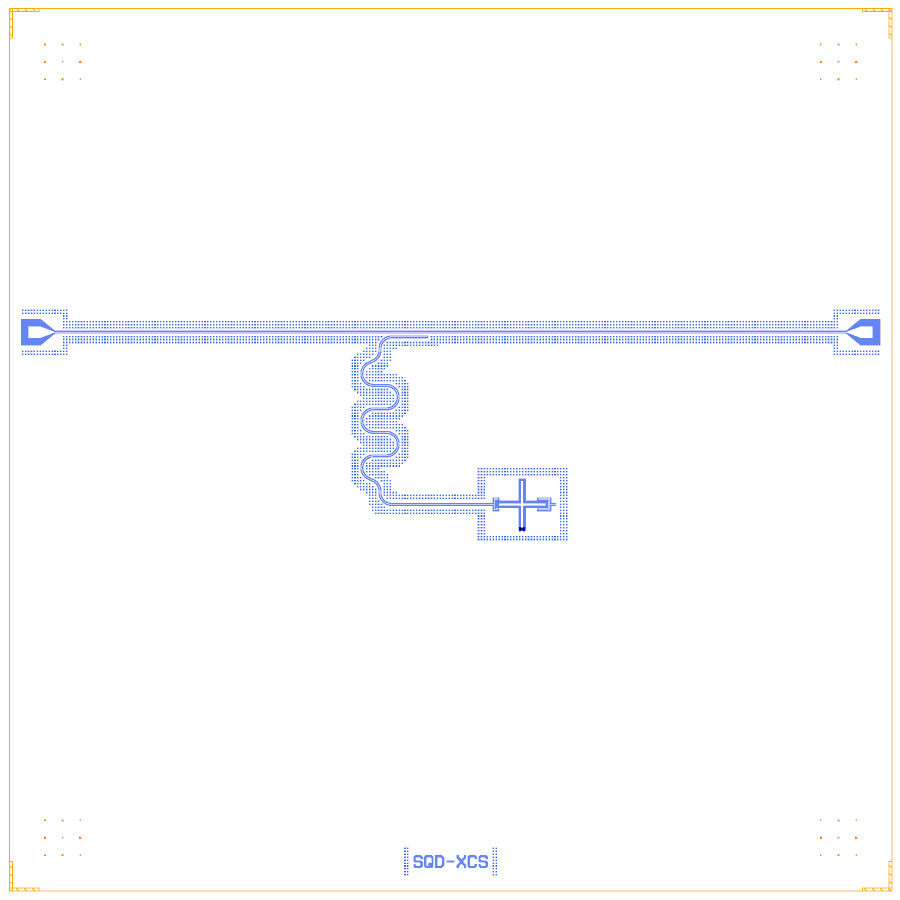

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `R1`.

{'TL': 6670.0, 'R1': 3700.0}


In [10]:
x_open = X0 - 200                                # the OpenToGround (source x -0.2 mm)
with d.batch():
    d.route("R1", q1.readout, tl.hanger(near=(x_open - 200, Y0), length=400, side="right", ground_gap=18,
                                        direction="forward", end="open"),
            meander=3700, r=99.9, nodes=[(x_open - 400, Y0 - 1464)])
layout_step(d, STEPS / "s5_readout.png", size=(900, 900), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 6 · Coupling: none (the bus claw stays open)

The cross has a second claw, `bus_01` (95 µm, west): in the source it is left unconnected, a coupler for a second
qubit that is not on this chip. It stays open here too.

## Design 7 · Routing: no control lines

The source has no drive, charge or flux line.

## Design 8 · The whole chip: sim group, centring, save

**Sim group, centring, save.** One sim group: the qubit, its readout and the line (a Q3D C-matrix — the source's
own analysis — and an eigenmode / EPR job). `center_in_die` applies the PDK placement rule: the content (the line
at y = 2200 down to the qubit at y ≈ 500) sat ≈ 214 µm above the die centre, so everything moves down by that
much (instance positions, waypoints and the hanger's `near` point; the pads stay on their edges). Then the design
is saved with `save_design`, which compares it with the file it replaces (the previous run's): it should say *same
design*, and the file keeps the previous key order.

centring shift (µm): (0.0, -213.8)


**Same design as before:** `examples/designs/sqdmetal/xmon_cap_sim.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer xmon_cap_sim: 3 instances, 2 routes, live=False> → examples\designs\sqdmetal\xmon_cap_sim.json | R1 3700.0 µm


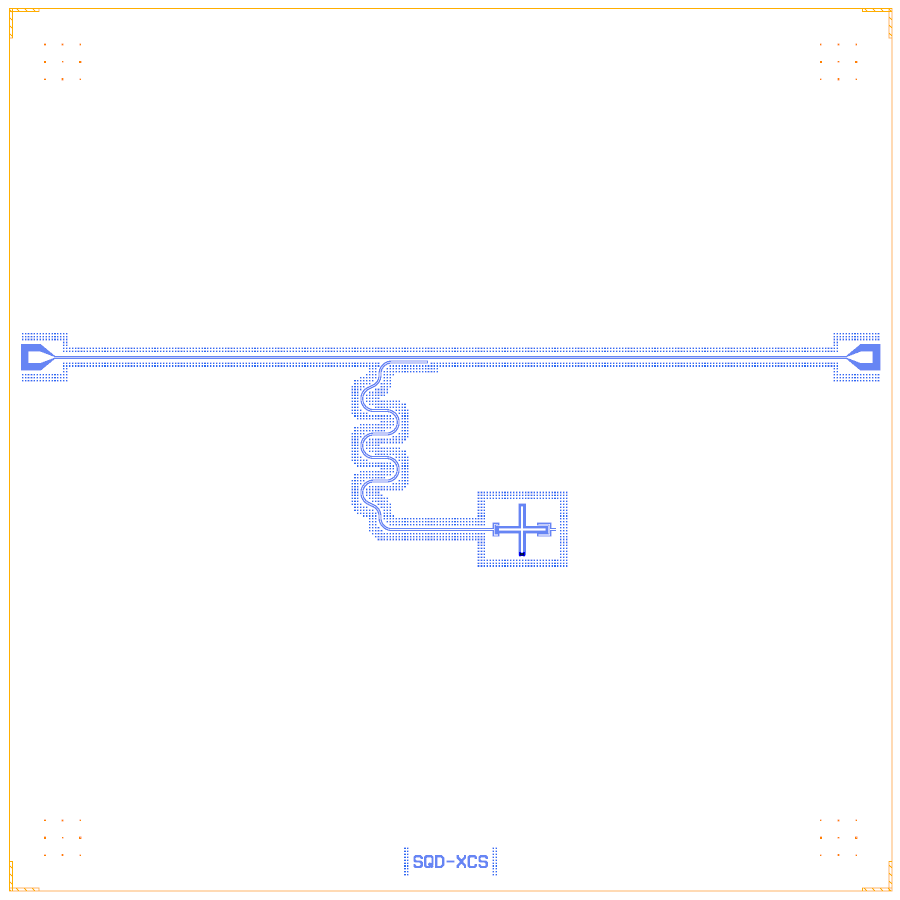

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/xmon_cap_sim/s8_chip.png')

In [11]:
d.sim_group("Q1R1", ["Q1", "R1", "TL"])
DX, DY = center_in_die(d)
print("centring shift (µm):", (DX, DY))
rebuild(d)
DESIGN, same = save_design(d, OUT / "xmon_cap_sim.json")
display(Markdown(same))
print(d, "→", DESIGN, "| R1", round(d.result.route_lengths()["R1"], 1), "µm")
layout_step(d, STEPS / "s8_chip.png", size=(900, 900), width=420)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here (from the v1 run): **no errors**; three `dangling_port` warnings, the open `bus_01` claw (the source leaves it
unconnected) and the junction attachment points `squid_a` / `squid_b`. No PDK design warning is expected:
`pdk_claw` reads bare numbers on Metal length options as µm, as the qcc Metal wrapper does (`claw_length: 95` =
95 µm; the check's units were fixed on 2026-11-04, it used to read mm and flag a 95 000 µm claw), and the
95 µm claw is well inside the 200 µm arms. `pdk_report` counts only the cells that draw a junction, so it should
read "Quantcore Junction × 1" (Q1; the launchpads are not counted).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` maps each component's ports onto circuit nodes. The `TransmonCross` is a grounded island (C and the
junction to ground) with one node per claw (C_g to the island, C to ground); the open `bus_01` claw stays a node
with only its capacitances (the netlist lists it as the one unconnected port). The readout between the claw and
an open end is a λ/2-type `TLres`; its open coupled section is a `HANGER` κ element to the line node, and the
launchpads are the line's two 50 Ω ports.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / R1 / TL ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.", "R1", "TL")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat normal modes of the whole circuit (frequencies, κ into the two 50 Ω launchpads, anharmonicities), then the
QuTiP-dressed values. The source states no frequencies (it extracts a capacitance matrix). Expected: f_q ≈ 6 GHz
with the nominal junction, α ≈ −180 MHz, and the open λ/2-type readout at ≈ 16 GHz (a 3.7 mm line between a
claw and an open end; on silicon too it would sit far above the qubit), with a small κ from the 400 µm open
coupled section. From the v1 run: f_q 5.787 GHz, α −198.9 MHz, f_r 16.11 GHz, χ −0.137 MHz.

In [ ]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes (QuCat; the circle is the qubit, the square the readout; filled
markers are the QuTiP dressed values), (b) the readout's dispersive shift |χ|. The readout sits ≈ 10 GHz above the
qubit (a 3.7 mm line between a claw and an open end), so χ is small.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="xmon_cap_sim: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The readout's coupling to the line is set by the coupled section: shorten it from 400 to 250 µm. The coupled-line
κ drops (roughly with the square of the coupled length) and the readout frequency barely moves (the total length
is unchanged). The waypoint before the coupled section sits at its start, so it moves with it (otherwise the
last vertical leg gets a jog shorter than two bends). Done on a copy (`design_copy`), so `xmon_cap_sim.json`
keeps the source's section.

In [ ]:
d2 = design_copy(DESIGN)
end, (nx, ny) = d2["R1"].spec["to"], d2["R1"].spec["nodes"][0]
d2["R1"].set(to=dict(end, length=250), nodes=[(end["near"][0] - 250 / 2, ny)])   # waypoint at the section start
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**R1 coupled section: 400 → 250 µm**\n\n" + params_delta_md(res, after)))
display(Markdown("| mode | κ before (MHz) | κ after (MHz) |\n|---|---|---|\n" + "\n".join(
    f"| {a.label} | {a.kappa_MHz:.3g} | {b.kappa_MHz:.3g} |" for a, b in zip(res.modes, after.modes))))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/sqdmetal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/sqdmetal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of the sim group (the source's own analysis)
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrix

The source's own run is this one, a capacitance matrix (Palace there, Q3D here): the cross, its two claws, the readout
and the line as named nets. Each net is named after its LOM node, so the matrix goes straight into the circuit
(Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, the line ends in the launchpads' 50 Ω
ports, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the
junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the line, where the readout's open coupled section shows up as a notch. The library
cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode`
does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds, the adaptive-mesh
frequency at the eigenmode's readout mode (the LOM's f_r, ≈ 16 GHz, before the eigenmode is solved) and a fast sweep
around it.

In [ ]:
f_r1 = res.params.get("R1.f_GHz")                        # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R1", jobs_eig["Q1R1"][0], keep_eig["Q1R1"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R1"]:
    display(Markdown(driven_md(keep_drv["Q1R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies as dashed
lines. The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "R1": f_r1}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's the
remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of
the 50 Ω-terminated box. The driven run adds the readout's S21 notch.

In [ ]:
fem_values = {}
if keep_eig["Q1R1"]:
    fem_values = epr_values(keep_eig["Q1R1"], {"Q1": "R1"}, {"R1": f_r1})
if keep_drv["Q1R1"]:
    fem_values.update({f"driven {k}": v for k, v in driven_values(keep_drv["Q1R1"], "R1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ from pyEPR and the "
          "readout's S21 notch.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name)
and the same LOM runs again — the comparison the source was made for (its own capacitance matrix). **FEM directly:**
the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
rows = []
if keep_q3d["Q1R1"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["Q1R1"]), max_modes=2).params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no frequencies, so this notebook sets one as an exercise: **Q1 at 6.0 GHz**, ≈ 0.21 GHz above where
the LOM puts it (from the v1 run: 5.787 GHz). It is reachable inside the PDK junction window: L_J goes from 6.73 nH
to ≈ 6.3 nH, R_n ≈ 42 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). The readout is not targeted: at
≈ 16 GHz it would need a line ≈ 2.4× longer to sit near the qubit, a redesign of the source rather than a feedback
step.

The targets go on a copy (`target_copy` → `build/xmon_cap_sim_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair — on the Q3D
values when a solve was kept — and picks one value per quantity (the consensus). `loop.feedback` anchors a surrogate
on that point and proposes the knobs that put the target inside its tolerance (f_q ± 20 MHz); the proposal is
written as revision 1, built and netlist-checked. The revision changes the LOM's L_J; the drawn junction keeps the
nominal 0.5 × 0.6 µm fingers until it is sized with `trilayer_junction("metal:TransmonCross", lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 6.0}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until the
target is inside its tolerance or `MAX_ITER` revisions are made (`build/xmon_cap_sim/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q3D job is exported and solved first
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value
against the target and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1R1",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `xmon_cap_sim.json` (saved in Design 8) is the whole design:
`qcc build examples/designs/sqdmetal/xmon_cap_sim.json` rebuilds `build/xmon_cap_sim.oas` + its sidecar, and the
KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and spacer 50–53/0, and the frame (100/0, 1000/0, 1001/0).
**Cheese:** the source has none (it meshes the design for Palace, `add_ground_plane()` with no holes), so the PDK
band stands — drawn in the build (`cheese_source` `build`), at least 4 µm clear of 3/0. Corner rounding is fab-only (`FULL_FAB`);
`qcc mask examples/designs/sqdmetal/xmon_cap_sim.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (the launchpads on the west / east edges); the cross transmon with both claws; its trilayer junction;
the open-ended coupled section under the line; the die frame's south-west corner (dicing L on 1000/0, 3 × 3
alignment grid on 1001/0); and the qubit in the **fab view** (the mask from Fab 1: 1/0 with the PDK cheese band,
the 3/0 keep-out, the junction layers). In the layout snapshots the chip boundary 100/0 is drawn as an outline and
the cheese band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

In [ ]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
cx, cy = d.data["routes"]["R1"]["to"]["near"]               # centre of the coupled section (after centring)
show_snapshot(d, OUT / "xmon_cap_sim.png", size=(1600, 1600), width=640)
show_snapshot(d, OUT / "xmon_cap_sim_q1.png", box=(qx - 400, qy - 300, qx + 400, qy + 300), size=(1200, 900), width=450)
show_snapshot(d, OUT / "xmon_cap_sim_jj.png", box=(qx - 40, qy - 260, qx + 40, qy - 180), width=300)
show_snapshot(d, OUT / "xmon_cap_sim_coupler.png", box=(cx - 280, cy - 140, cx + 260, cy + 40), size=(1620, 540), width=560)
show_snapshot(d, OUT / "xmon_cap_sim_frame.png", box=(-1450, -2550, -550, -1650), size=(900, 900), width=300)
snap_file(Path("build") / "xmon_cap_sim_fab.oas", OUT / "xmon_cap_sim_fab_q1.png",
          box=(qx - 400, qy - 400, qx + 400, qy + 400), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | the `TransmonCross` with the source's claws (95 µm `bus_01` left open), the launchpads, the 3.7 mm readout with its open coupled section 40 µm from the line at the source's position, the Q3D sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; launchpads moved to the die edges (outer etch 100 µm), so the line is 2.7 mm longer; content centred (moved ≈ 214 µm down); sapphire; the PDK nominal trilayer junction (the source has none); the PDK cheese band in the mask |
| **substituted** | meander + `OpenToGround` as one open hanger route; the line as a straight route |
| **PDK design warnings** | none expected (the `pdk_claw` check now reads `claw_length: 95` as 95 µm) |
| layout | built in eight segments (die, launchpads, line, qubit, readout; no coupling and no control lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 6.0 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn junction stays nominal (size it with `trilayer_junction`) |